# Planning a synthetic-control intervention

A later synthetic-control analysis is only useful if the panel can support it. This page plans one intervention on `unit_a` before that analysis exists. The outcome is a generic level, not a budget or a geography. The question is how long to run the intervention, or whether not to launch.

The rule is fixed before any fit. Carry forward the shortest duration whose false-positive rate stays within a predeclared tolerance, whose cumulative interval meets a predeclared precision target, and whose minimum detectable effect is at or below a predeclared worthwhile effect. If neither duration qualifies, do not launch. Do not add a duration, a donor, or a search after seeing the curve.

The panel has 48 periods and four reserved blocks: a training core, two selection rehearsals, an untouched audit, and a future-test tail. Rehearsals are computed before the audit is used, and the audit is not used to choose the duration. The power study uses only the future-test tail.


## The decision, before the fit

{term}`Synthetic control` compares a treated unit with a weighted combination of donors {cite:p}`abadie2010synthetic`. A good fit in the training window is not evidence that the same weights will track the {term}`counterfactual` after the intervention. The planning question is whether a declared effect would be detectable, and whether the donors support that comparison at all.

Two donor pools are fixed before any fit. The credible pool is built so that `unit_a` is a noisy equal-weight combination of those donors. The contrasting pool tracks `unit_a` through the training window and then leaves it for the audit only. The second pool is the unsuitable design: it can look attractive before the intervention and still fail the comparison that the analysis needs.

The later comparison identifies an effect of the intervention only if the donors stay untreated, the intervention is not anticipated, and one unit's outcome does not interfere with another's. Those are assignment assumptions, declared here, not results. The audit checks whether a pool can track `unit_a`. It does not test them.

The duration comparison uses only the credible pool. A missing decision rate is not a low rate. A posterior tail probability is not power.


In [1]:
import contextlib
import io
import logging
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

import causalpy as cp
from causalpy.planning.contracts import DecisionRule, PowerCriterion
from causalpy.planning.power import (
    NOISE_TO_DONOR_SD,
    ReferencePowerEvaluator,
    replicates_for_tolerance,
)
from causalpy.planning.reference import HistoryOnlyPlan
from causalpy.planning.report import evaluation_table, plot_evaluation

%matplotlib inline

SEED = 1442
N_PERIODS = 48
TRAINING_CORE = range(0, 24)
REHEARSAL_A = range(24, 28)
REHEARSAL_B = range(28, 32)
AUDIT = range(32, 40)
FUTURE_TEST = range(40, 48)
DURATIONS = (4, 8)
TARGET_POWER = 0.8
FALSE_POSITIVE_TOLERANCE = 0.15
MONTE_CARLO_TOLERANCE = 0.09
HDI_PROB = 0.94
FIG_WIDTH = 7
FIG_HEIGHT = 3.4
COLOR_TREATED = "#0b3a53"
COLOR_CREDIBLE = "#1b7f4e"
COLOR_CONTRAST = "#b85c38"
COLOR_COUNTERFACTUAL = "#5f6f7a"
COLOR_SHORT = "#1d4e89"
COLOR_LONG = "#0e7c86"
CREDIBLE = ("unit_b", "unit_c", "unit_d", "unit_e")
CONTRAST = ("unit_f", "unit_g", "unit_h")
CONTRAST_OFFSET = {"unit_f": 1.2, "unit_g": -1.2, "unit_h": 0.4}
AUDIT_SHIFT = 3.0

SAMPLE_KWARGS = {
    "draws": 500,
    "tune": 500,
    "chains": 4,
    "progressbar": False,
    "target_accept": 0.95,
    "random_seed": SEED,
}


class _QuietSampling:
    """Hide sampler banners. Re-emit donor-support warnings."""

    def __enter__(self):
        self._out = io.StringIO()
        self._err = io.StringIO()
        self._stdout = contextlib.redirect_stdout(self._out)
        self._stderr = contextlib.redirect_stderr(self._err)
        self._stdout.__enter__()
        self._stderr.__enter__()
        logging.disable(logging.WARNING)
        self._warnings = warnings.catch_warnings(record=True)
        self._caught = self._warnings.__enter__()
        return self

    def __exit__(self, exc_type, exc, tb):
        self._warnings.__exit__(exc_type, exc, tb)
        logging.disable(logging.NOTSET)
        self._stderr.__exit__(exc_type, exc, tb)
        self._stdout.__exit__(exc_type, exc, tb)
        if exc_type is not None and self._err.getvalue():
            print(self._err.getvalue()[-2000:])
        elif exc_type is None:
            for item in self._caught:
                if issubclass(item.category, UserWarning):
                    warnings.warn(str(item.message), item.category, stacklevel=2)
        return False


def _style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def _hdi(draws):
    interval = az.hdi(np.asarray(draws).ravel(), prob=HDI_PROB)
    return float(interval[0]), float(interval[1])

## One simulated panel

The credible donors share one latent factor and independent noise. `unit_a` is their equal-weight mean plus a smaller noise term, so the training window can support a convex combination. That construction is the data-generating process, not a result of the fit.

The contrasting donors copy `unit_a` through period 31, with fixed offsets wide enough that `unit_a` stays inside their range. During the audit, periods 32–39, they all shift up by the same amount, then return to the unshifted path. A convex combination cannot track a unit that every donor has left for that window. The shift is the unsuitable design for the audit, and it is in the data before any model runs. It is not a permanent departure, and it does not cover the future-test tail.


In [2]:
rng = np.random.default_rng(SEED)
factor = np.cumsum(rng.normal(0.0, 1.0, N_PERIODS))
donor_noise = rng.normal(0.0, 1.0, size=(N_PERIODS, len(CREDIBLE)))
donors = pd.DataFrame(factor[:, None] + donor_noise, columns=CREDIBLE)
noise_scale = float(NOISE_TO_DONOR_SD * donors.std(ddof=1).mean())
frame = donors.copy()
frame["unit_a"] = donors.mean(axis=1) + rng.normal(0.0, noise_scale, N_PERIODS)
for name, offset in CONTRAST_OFFSET.items():
    frame[name] = frame["unit_a"] + offset + rng.normal(0.0, noise_scale, N_PERIODS)
frame.loc[AUDIT, list(CONTRAST)] += AUDIT_SHIFT
frame.index.name = "period"

training = frame.loc[: AUDIT.start - 1]
assert (training[list(CREDIBLE)].min(axis=1) <= training["unit_a"]).all()
assert (training[list(CREDIBLE)].max(axis=1) >= training["unit_a"]).all()
assert (training[list(CONTRAST)].min(axis=1) <= training["unit_a"]).all()
assert (training[list(CONTRAST)].max(axis=1) >= training["unit_a"]).all()
audit_rows = frame.loc[AUDIT]
assert (audit_rows[list(CONTRAST)].min(axis=1) > audit_rows["unit_a"]).all()
frame.head()

,unit_b,unit_c,unit_d,unit_e,unit_a,unit_f,unit_g,unit_h
period,,,,,,,,
0,2.899244,4.354150,-0.076763,2.143258,2.360635,3.624560,1.351021,2.691982
1,0.946423,-0.766015,-0.161487,0.725672,0.553900,1.885959,-0.814758,0.809325
2,-0.820861,-0.027412,0.278087,-0.652803,-0.361131,0.438175,-1.856661,0.117004
3,-1.019959,1.647066,0.433954,-3.309157,-0.555166,0.554954,-1.841883,-0.043153
4,0.235938,1.621143,0.502908,2.096211,1.056116,2.250575,-0.062807,1.528617


The assertions above are design checks, not fit results. Through period 31, `unit_a` lies between the donors in each pool. In the audit window, every contrasting donor is above `unit_a`.

The decision threshold is one standard deviation of the credible donors, on the cumulative total, computed before any fit. A threshold of zero sits inside this estimator's null estimation error, so a zero bar is not a false-positive control. The worthwhile effect is one sixth of that standard deviation per period. Four periods then accumulate less than the threshold, and eight periods accumulate more. The split is a consequence of tail length, written down before the curve. The precision target is the same donor standard deviation: the cumulative interval has to be no wider than the bar the decision uses.


In [3]:
donor_sd = float(np.std(frame[list(CREDIBLE)].to_numpy(dtype=float)))
decision = DecisionRule(
    estimand="cumulative_total",
    threshold=donor_sd,
    direction="positive",
    probability=TARGET_POWER,
)
WORTHWHILE = float(donor_sd / 6.0)
EFFECTS = (
    0.0,
    donor_sd / 12.0,
    donor_sd / 8.0,
    WORTHWHILE,
    donor_sd / 4.0,
    donor_sd / 3.0,
)
PRECISION_TARGET = float(donor_sd)
criterion = PowerCriterion(
    target_power=TARGET_POWER,
    false_positive_tolerance=FALSE_POSITIVE_TOLERANCE,
    precision_target=PRECISION_TARGET,
    monte_carlo_error_tolerance=MONTE_CARLO_TOLERANCE,
    qualification_scope="fixed_design",
)
replicates = replicates_for_tolerance(
    MONTE_CARLO_TOLERANCE,
    n_durations=len(DURATIONS),
)
assert replicates * len(DURATIONS) <= 64
pd.Series(
    {
        "donor standard deviation": donor_sd,
        "decision threshold": decision.threshold,
        "worthwhile effect": WORTHWHILE,
        "precision target": PRECISION_TARGET,
        "replicates per duration": replicates,
    }
)

donor standard deviation     3.148834
decision threshold           3.148834
worthwhile effect            0.524806
precision target             3.148834
replicates per duration     31.000000
dtype: float64

## What the estimand is

The future-test tail is periods 40–47. Nothing in that tail is treated as observed. One planning evaluation on the simulated panel shows the objects the later choice will use: the holdout counterfactual, a translated effect, and the uncertainty on that translation. The zero column is the observed series with no added translation. It is not a repeated-experiment null. This fit does not choose the duration.

`HistoryOnlyPlan` places the intervention at the end of the supplied frame. Passing the full panel and asking for eight periods makes periods 40–47 the holdout. The treated column here is the simulated series, so the figure is a simulated demonstration, not an analysis of an intervention that has happened.


In [4]:
plan = HistoryOnlyPlan(
    frame,
    "unit_a",
    CREDIBLE,
    decision,
    estimator="synthetic_control",
    sample_kwargs=SAMPLE_KWARGS,
    outcome_scale="outcome units",
)
future = plan.analysis_handoff(duration=8)
assert list(future.holdout_index) == list(FUTURE_TEST)
assert list(future.training_index) == list(range(0, 40))

with _QuietSampling():
    demonstration = plan.evaluate(8, absolute_effects=(0.0, WORTHWHILE))


def evaluation_at(result, magnitude):
    matches = [
        item for item in result.evaluations if item.scenario.magnitude == magnitude
    ]
    if len(matches) != 1:
        raise RuntimeError(f"Expected one evaluation at {magnitude}.")
    return matches[0]


zero_effect = evaluation_at(demonstration, 0.0)
worthwhile_effect = evaluation_at(demonstration, WORTHWHILE)
holdout = list(zero_effect.draws.unit_impact.obs_ind.values)
assert holdout == list(FUTURE_TEST)
evaluation_table(demonstration)

,estimator,duration,effect_scale,effect_magnitude,cumulative_total_mean,average_per_period_mean,average_per_treated_unit_mean,relative_total_mean,posterior_tail_probability,decided,hdi_covers_threshold,repeated_experiment_power,historical_detection_share
0,synthetic_control,8,absolute,0.000000,0.444377,0.055547,0.444377,None,0.0,False,False,None,None
1,synthetic_control,8,absolute,0.524806,4.642823,0.580353,4.642823,None,1.0,True,False,None,None


The `decided` column is this one experiment's rule. True means the posterior probability above the threshold reached the target on this fit. It is not the launch choice. That choice is the later table of rates across replicates. On the worthwhile row, `hdi_covers_threshold` is False because that interval sits above the threshold. False is not a failed demonstration.


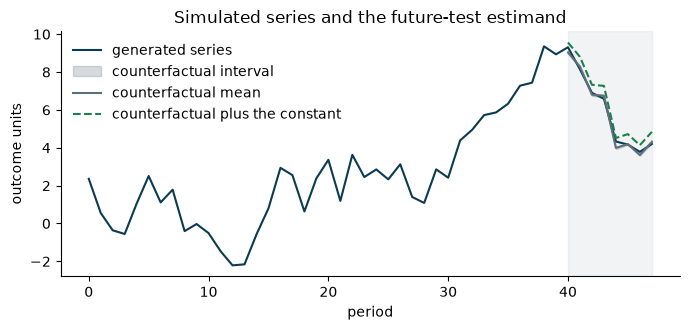

In [5]:
counterfactual = zero_effect.draws.counterfactual.sel(treated_units="unit_a")
cf_mean = counterfactual.mean(dim=("chain", "draw"))
cf_lower, cf_upper = [], []
for label in holdout:
    lo, hi = _hdi(counterfactual.sel(obs_ind=label).values)
    cf_lower.append(lo)
    cf_upper.append(hi)
constant_translation = cf_mean.values + WORTHWHILE

fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))
ax.plot(frame.index, frame["unit_a"], color=COLOR_TREATED, label="generated series")
ax.fill_between(
    holdout,
    cf_lower,
    cf_upper,
    color=COLOR_COUNTERFACTUAL,
    alpha=0.25,
    label="counterfactual interval",
)
ax.plot(
    holdout, cf_mean.values, color=COLOR_COUNTERFACTUAL, label="counterfactual mean"
)
ax.plot(
    holdout,
    constant_translation,
    color=COLOR_CREDIBLE,
    linestyle="--",
    label="counterfactual plus the constant",
)
ax.axvspan(
    FUTURE_TEST.start, FUTURE_TEST.stop - 1, color=COLOR_COUNTERFACTUAL, alpha=0.08
)
_style_axis(ax)
ax.set_xlabel("period")
ax.set_ylabel("outcome units")
ax.set_title("Simulated series and the future-test estimand")
ax.legend(frameon=False)
fig.tight_layout()

The dashed line is the counterfactual mean plus the constant per-period effect. It is not a second fitted model. The generated series and the counterfactual can differ inside the future-test window because the counterfactual is a posterior prediction, not a copy of the simulated treated column.

The planning plot below is the public impact path: the fitted residual plus that same constant, so the path wiggles. The dashed line on that plot is the constant. The wiggle is this one simulated series, not a time-varying effect. The interval is one fit's posterior uncertainty. It is not the decision rate. The next decision is the later table of rates across replicates, not this interval. The horizontal axis counts holdout periods from zero; the figure above uses the panel index.


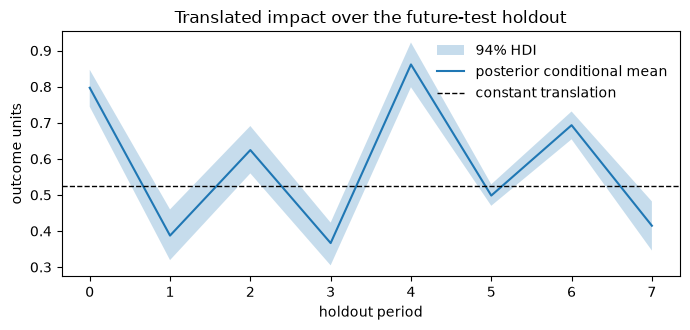

In [6]:
impact = plot_evaluation(worthwhile_effect)
impact.axes[0].axhline(
    WORTHWHILE,
    color="black",
    linestyle="--",
    linewidth=1,
    label="constant translation",
)
impact.axes[0].legend(frameon=False)
impact.axes[0].set_title("Translated impact over the future-test holdout")
impact.axes[0].set_ylabel("outcome units")
impact.set_size_inches(FIG_WIDTH, FIG_HEIGHT)
impact.tight_layout()

## The reserved timeline

Selection rehearsals and the audit are design choices, not a grouped search. The planner has no method that returns those windows. They are slices of the same panel, each evaluated with `HistoryOnlyPlan` on a frame that ends at the window of interest.

Periods 0–23 are the training core. Periods 24–27 and 28–31 are the rehearsals: earlier slices the planner would fit if someone were choosing a window after seeing estimates. Periods 32–39 are the untouched audit. Periods 40–47 are the future-test candidates. The audit does not overlap the future test.

A duration is a tail length, not a common origin. Duration 4 on the full panel holds out periods 44–47 and therefore trains through period 43. Duration 8 holds out periods 40–47 and trains through period 39. The two arms do not share a training window. The short arm's extra training is early future-test history, which a real study would not have yet. That is a property of tail-length comparison, and the notebook does not hide it.


In [7]:
def window_plan(last_period, controls):
    history = frame.loc[:last_period].copy()
    planned = HistoryOnlyPlan(
        history,
        "unit_a",
        controls,
        decision,
        estimator="synthetic_control",
        sample_kwargs=SAMPLE_KWARGS,
        outcome_scale="outcome units",
    )
    return planned


windows = (
    ("rehearsal A", REHEARSAL_A),
    ("rehearsal B", REHEARSAL_B),
    ("audit", AUDIT),
)
window_rows = []
for label, periods in windows:
    planned = window_plan(periods.stop - 1, CREDIBLE)
    spec = planned.analysis_handoff(duration=len(periods))
    assert list(spec.holdout_index) == list(periods)
    window_rows.append(
        {
            "window": label,
            "holdout": f"{periods.start}–{periods.stop - 1}",
            "training through": spec.training_index[-1],
            "treatment time": spec.treatment_time,
        }
    )
short_arm = plan.analysis_handoff(duration=4)
long_arm = plan.analysis_handoff(duration=8)
window_rows.extend(
    [
        {
            "window": "duration 4",
            "holdout": f"{short_arm.holdout_index[0]}–{short_arm.holdout_index[-1]}",
            "training through": short_arm.training_index[-1],
            "treatment time": short_arm.treatment_time,
        },
        {
            "window": "duration 8",
            "holdout": f"{long_arm.holdout_index[0]}–{long_arm.holdout_index[-1]}",
            "training through": long_arm.training_index[-1],
            "treatment time": long_arm.treatment_time,
        },
    ]
)
pd.DataFrame(window_rows)

,window,holdout,training through,treatment time
0,rehearsal A,24–27,23,24
1,rehearsal B,28–31,27,28
2,audit,32–39,31,32
3,duration 4,44–47,43,44
4,duration 8,40–47,39,40


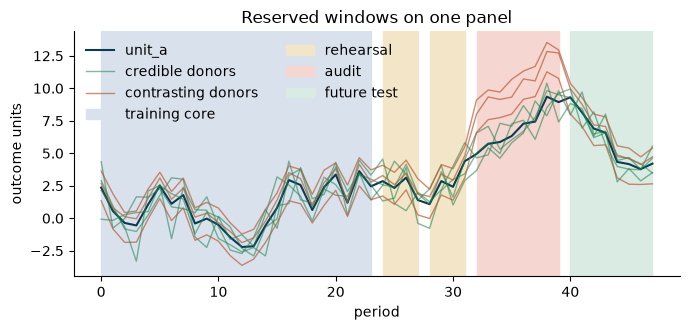

In [8]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))
ax.plot(frame.index, frame["unit_a"], color=COLOR_TREATED, label="unit_a")
for index, name in enumerate(CREDIBLE):
    ax.plot(
        frame.index,
        frame[name],
        color=COLOR_CREDIBLE,
        alpha=0.55,
        linewidth=1,
        label="credible donors" if index == 0 else None,
    )
for index, name in enumerate(CONTRAST):
    ax.plot(
        frame.index,
        frame[name],
        color=COLOR_CONTRAST,
        alpha=0.7,
        linewidth=1,
        label="contrasting donors" if index == 0 else None,
    )
bands = (
    (TRAINING_CORE, "#d9e2ec", "training core"),
    (REHEARSAL_A, "#f3e6c8", "rehearsal"),
    (REHEARSAL_B, "#f3e6c8", None),
    (AUDIT, "#f6d6d0", "audit"),
    (FUTURE_TEST, "#d9ebe3", "future test"),
)
for periods, color, label in bands:
    ax.axvspan(periods.start, periods.stop - 1, color=color, label=label, zorder=0)
_style_axis(ax)
ax.set_xlabel("period")
ax.set_ylabel("outcome units")
ax.set_title("Reserved windows on one panel")
ax.legend(frameon=False, ncol=2)
fig.tight_layout()

Green lines are the credible donors. Rust lines are the contrasting donors. The bands are reserved blocks, not fitted regions. No donor has been selected from these estimates, because no estimate has been used to select one. The next decision is whether each pool can track `unit_a` through the audit, not which band looks calm.


## Do the donors support the comparison?

The donor check is a planning diagnostic. It asks whether each pool can track `unit_a` before the audit and whether that track survives the audit window. It is not the intervention result, and it is not the duration decision.

The planning result stores the holdout prediction and the translated impact. It does not return the training-period trajectory. The figure below uses `SyntheticControl` because that public analysis plot already draws both windows. Here the pre-period is every period before the audit, including the rehearsals, because the unsuitable shift is periods 32–39 only. The fit uses the standard analysis class and the same sampling settings. It does not choose the duration, and its impact panels are not the estimand in the choice rule. The planning API remains the source of the signed estimates, the power, and the handoff.

The tracking-gap panels are the gap between `unit_a` and the donor combination. No intervention was applied. The vertical line is the audit start. The contrast gap after that line is the planted shift. A training-window fit near one is not validation that the untreated path is a convex combination of the donors.

A convex-hull warning, if the fit prints one, means the treated unit left the donor range. That is information about support. It is not a reason to edit the model or to drop a donor after seeing the audit.


/var/folders/r0/nf1kgxsx6zx3rw16xc3wnnzr0000gn/T/ipykernel_15202/626635991.py:54: UserWarning: The figure layout has changed to tight


/var/folders/r0/nf1kgxsx6zx3rw16xc3wnnzr0000gn/T/ipykernel_15202/626635991.py:54: UserWarning: The figure layout has changed to tight


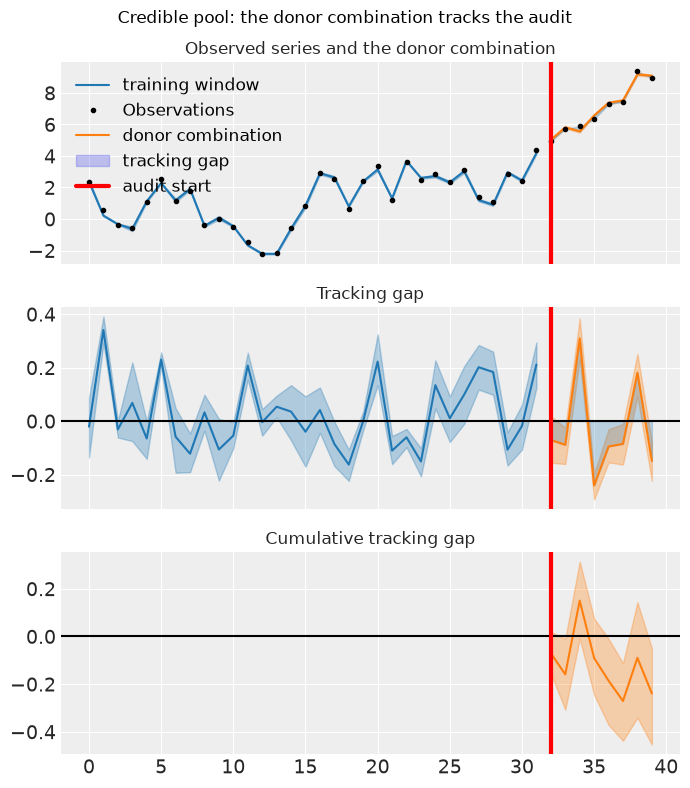

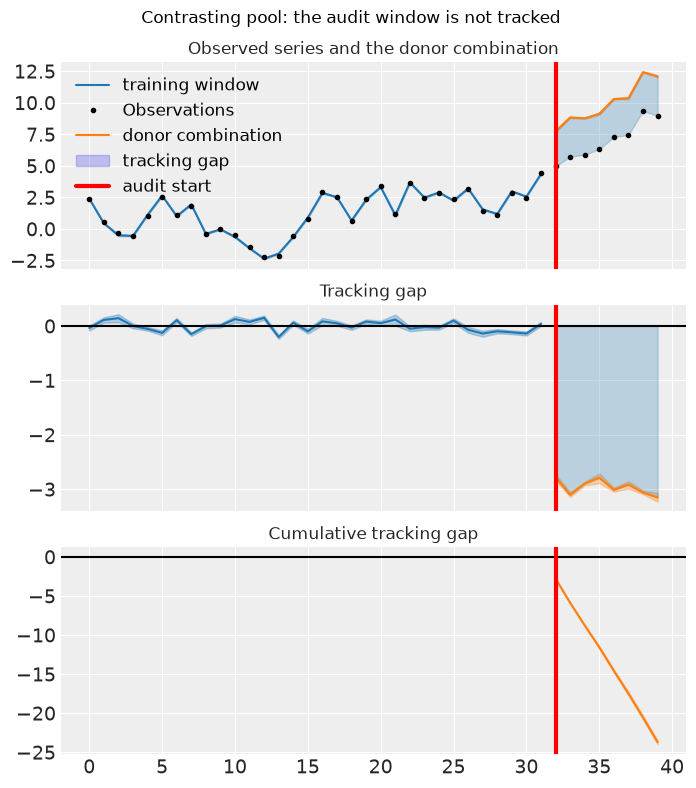

In [9]:
def _tracking_label(label):
    lowered = label.lower()
    if "causal impact" in lowered:
        return "tracking gap"
    if "pre-intervention" in lowered or "treatment" in lowered:
        return "audit start" if "treatment" in lowered else "training window"
    if label == "Counterfactual":
        return "donor combination"
    return label


def donor_support(controls, title):
    history = frame.loc[: AUDIT.stop - 1, ["unit_a", *controls]].copy()
    with _QuietSampling():
        fitted = cp.SyntheticControl(
            history,
            AUDIT.start,
            control_units=list(controls),
            treated_units=["unit_a"],
            model=cp.pymc_models.WeightedSumFitter(sample_kwargs=SAMPLE_KWARGS),
        ).fit()
    fig, axes = fitted.plot(
        plot_predictors=False,
        figsize=(FIG_WIDTH, FIG_HEIGHT * 2.35),
        show=False,
    )
    axes[0].set_title("Observed series and the donor combination")
    axes[1].set_title("Tracking gap")
    axes[2].set_title("Cumulative tracking gap")
    for line in axes[0].get_lines():
        color = line.get_color()
        if color in {"r", "red"} or (
            isinstance(color, tuple)
            and len(color) >= 3
            and color[0] > 0.9
            and color[1] < 0.1
            and color[2] < 0.1
        ):
            line.set_label("audit start")
    legend = axes[0].get_legend()
    if legend is None:
        handles, labels = [], []
        fontsize = 10
    else:
        handles = list(legend.legend_handles)
        labels = [_tracking_label(text.get_text()) for text in legend.get_texts()]
        fontsize = legend.get_texts()[0].get_fontsize()
    for line in axes[0].get_lines():
        if line.get_label() == "audit start" and line not in handles:
            handles.append(line)
            labels.append("audit start")
    axes[0].legend(handles, labels, frameon=False, fontsize=fontsize)
    fig.suptitle(title)
    fig.tight_layout()


donor_support(CREDIBLE, "Credible pool: the donor combination tracks the audit")
donor_support(CONTRAST, "Contrasting pool: the audit window is not tracked")

The credible pool is the comparison the power study is allowed to use. The contrasting pool is the unsuitable design: the training window can look close while the audit window cannot be tracked, because every contrasting donor sits above `unit_a` there. A small training error would not repair that. The audit trajectory is the evidence. A missing rate is not.

These two fits are donor-support checks. The next section's signed estimates come from `HistoryOnlyPlan.evaluate` on the same windows, not from the tracking-gap panels above.


## Signed estimates are not a search

Each reserved window is a separate tail. The estimate is the posterior mean of the cumulative total at a zero effect, with the posterior interval. A window whose interval sits on zero is a holdout check. It is not a license to pick that window because the estimate looks friendly.

The two rehearsals are shown first. The audit is shown after them. Nothing in this section chooses a duration or a donor pool. The duration grid was declared before these fits.


In [10]:
signed_rows = []
for pool_name, controls in (("credible", CREDIBLE), ("contrast", CONTRAST)):
    for label, periods in windows:
        planned = window_plan(periods.stop - 1, controls)
        with _QuietSampling():
            fitted = planned.evaluate(len(periods), absolute_effects=(0.0,))
        evaluation = fitted.evaluations[0]
        assert list(evaluation.draws.unit_impact.obs_ind.values) == list(periods)
        lo, hi = evaluation.summary.cumulative_total_hdi
        signed_rows.append(
            {
                "pool": pool_name,
                "window": label,
                "holdout": f"{periods.start}–{periods.stop - 1}",
                "cumulative mean": evaluation.summary.cumulative_total_mean,
                "lower": lo,
                "upper": hi,
                "tail probability": evaluation.decision.posterior_tail_probability,
            }
        )
signed = pd.DataFrame(signed_rows)
signed

The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


,pool,window,holdout,cumulative mean,lower,upper,tail probability
0,credible,rehearsal A,24–27,0.523105,0.321331,0.714267,0.0
1,credible,rehearsal B,28–31,0.326890,0.154353,0.480291,0.0
2,credible,audit,32–39,-0.239212,-0.453655,-0.049586,0.0
3,contrast,rehearsal A,24–27,-0.265370,-0.471689,-0.027594,0.0
4,contrast,rehearsal B,28–31,-0.361257,-0.509752,-0.219224,0.0
5,contrast,audit,32–39,-23.717084,-23.994733,-23.462269,0.0


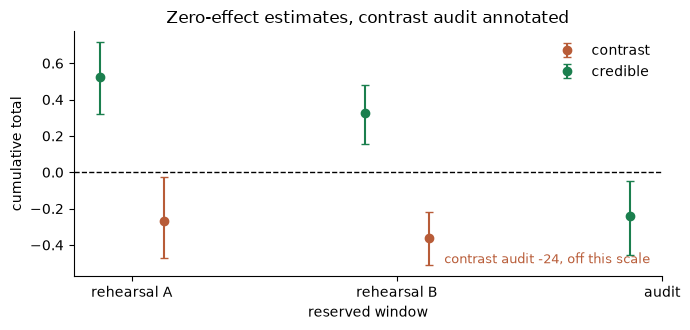

In [11]:
shown = signed[~((signed["pool"] == "contrast") & (signed["window"] == "audit"))]
audit = signed[(signed["pool"] == "contrast") & (signed["window"] == "audit")].iloc[0]
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))
positions = {"rehearsal A": 0, "rehearsal B": 1, "audit": 2}
offsets = {"credible": -0.12, "contrast": 0.12}
colors = {"credible": COLOR_CREDIBLE, "contrast": COLOR_CONTRAST}
for pool_name, group in shown.groupby("pool"):
    x = [positions[label] + offsets[pool_name] for label in group["window"]]
    mean = group["cumulative mean"].to_numpy()
    yerr = np.vstack([mean - group["lower"], group["upper"] - mean])
    ax.errorbar(
        x,
        mean,
        yerr=yerr,
        fmt="o",
        color=colors[pool_name],
        label=pool_name,
        capsize=3,
    )
ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
ax.text(
    0.98,
    0.04,
    f"contrast audit {audit['cumulative mean']:.0f}, off this scale",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    color=COLOR_CONTRAST,
    fontsize=9,
)
_style_axis(ax)
ax.set_xticks(list(positions.values()), list(positions))
ax.set_ylabel("cumulative total")
ax.set_xlabel("reserved window")
ax.set_title("Zero-effect estimates, contrast audit annotated")
ax.legend(frameon=False)
fig.tight_layout()

The credible deviations are tenths of an outcome unit. The contrast audit is tens of units, and it is the window that breaks the comparison. The rehearsals do not sit on zero for either pool, so the friendlier rehearsal is not evidence that the audit will hold. The duration study does not pick among these windows. The fits print an effective-sample-size warning: some parameters have fewer than 100 effective draws per chain. That is a reason not to rank these intervals more finely than the displayed tenths. Every interval in the table still excludes zero. The off-zero claim is that exclusion, not the point means alone.


## Power is a rate, not a tail probability

The power study replaces `unit_a` with a generated untreated series and translates effects onto the future-test tail. The generator is `correctly_specified_noisy_reference`: an equal-weight combination of the observed donors plus independent noise, drawn again for each replicate. Donor columns stay fixed. Treatment is not in the series the estimator fits. One evaluation of one generated panel shows the posterior of the cumulative total under a zero effect and under the worthwhile effect. The study then reports the share of experiments whose decision rule fires. Those are different objects. The left panel of the figure is one experiment. The right panel is the repeated-experiment rate.

The fit count does not grow with the effect grid. Two durations at this Monte Carlo tolerance are 62 fits, and the ceiling is 64. A third duration would be a new study, not a line added to this one.


In [12]:
evaluator = ReferencePowerEvaluator(
    plan,
    history=frame,
    scenario_family="correctly_specified_noisy_reference",
)
assert evaluator.scenario_family == "correctly_specified_noisy_reference"
one_panel = evaluator.untreated_panel(0)
one_plan = HistoryOnlyPlan(
    one_panel,
    "unit_a",
    CREDIBLE,
    decision,
    estimator="synthetic_control",
    sample_kwargs=SAMPLE_KWARGS,
    outcome_scale="outcome units",
)
with _QuietSampling():
    one_experiment = one_plan.evaluate(8, absolute_effects=(0.0, WORTHWHILE))
one_zero = evaluation_at(one_experiment, 0.0)
one_worth = evaluation_at(one_experiment, WORTHWHILE)

with _QuietSampling():
    power = evaluator.effect_by_duration(
        DURATIONS,
        EFFECTS,
        decision=decision,
        criterion=criterion,
        scale="absolute",
        minimum_worthwhile_effect=WORTHWHILE,
    )
assert power.n_fits == replicates * len(DURATIONS)
assert power.n_replicates == replicates
assert power.power_withheld is False
power.frame().head()

/var/folders/r0/nf1kgxsx6zx3rw16xc3wnnzr0000gn/T/ipykernel_15202/2754853920.py:22: UserWarning: Convex hull assumption may be violated: 1 pre-intervention time points (0.0% above, 2.3% below control range). The synthetic control method requires the treated unit to lie within the convex hull of control units. Consider: (1) adding more diverse control units, (2) using a model with an intercept (e.g., ITS with control predictors), or (3) using the Augmented Synthetic Control Method. See glossary term 'Convex hull condition' for more details.
/var/folders/r0/nf1kgxsx6zx3rw16xc3wnnzr0000gn/T/ipykernel_15202/2754853920.py:22: UserWarning: Convex hull assumption may be violated: 1 pre-intervention time points (0.0% above, 2.5% below control range). The synthetic control method requires the treated unit to lie within the convex hull of control units. Consider: (1) adding more diverse control units, (2) using a model with an intercept (e.g., ITS with control predictors), or (3) using the Augmen

,duration,effect,scale,probability,monte_carlo_error,n_decided,n_replicates,posterior_mean,posterior_tail_mean,interval_width,...,false_positive_rate,wrong_sign_rate,detection,failed_runs,precision_met,minimum_worthwhile_effect,scenario_family,power_withheld,baseline,false_positive_within_tolerance
0,4,0.000000,absolute,0.000000,0.000000,0,31,0.044047,0.000000,0.335371,...,0.0,NaN,0.000000,0,True,0.524806,correctly_specified_noisy_reference,False,None,True
1,4,0.262403,absolute,0.000000,0.000000,0,31,1.093658,0.000000,0.335371,...,0.0,0.0,0.000000,0,True,0.524806,correctly_specified_noisy_reference,False,None,True
2,4,0.393604,absolute,0.000000,0.000000,0,31,1.618464,0.000000,0.335371,...,0.0,0.0,0.000000,0,True,0.524806,correctly_specified_noisy_reference,False,None,True
3,4,0.524806,absolute,0.000000,0.000000,0,31,2.143270,0.000000,0.335371,...,0.0,0.0,0.000000,0,True,0.524806,correctly_specified_noisy_reference,False,None,True
4,4,0.787209,absolute,0.548387,0.089381,17,31,3.192881,0.630581,0.335371,...,0.0,0.0,0.548387,0,True,0.524806,correctly_specified_noisy_reference,False,None,True


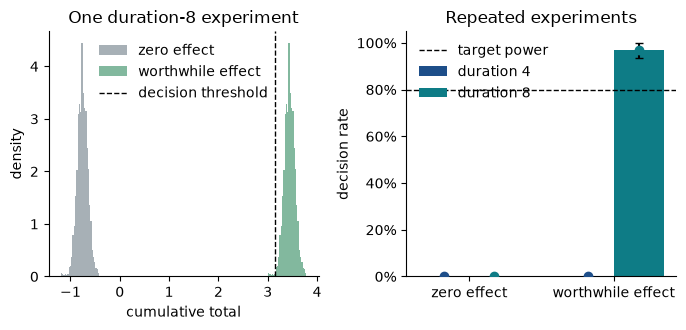

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, FIG_HEIGHT))
for evaluation, color, label in (
    (one_zero, COLOR_COUNTERFACTUAL, "zero effect"),
    (one_worth, COLOR_CREDIBLE, "worthwhile effect"),
):
    draws = np.asarray(evaluation.draws.cumulative_total.values).ravel()
    axes[0].hist(draws, bins=30, density=True, alpha=0.55, color=color, label=label)
axes[0].axvline(
    decision.threshold,
    color="black",
    linestyle="--",
    linewidth=1,
    label="decision threshold",
)
_style_axis(axes[0])
axes[0].set_xlabel("cumulative total")
axes[0].set_ylabel("density")
axes[0].set_title("One duration-8 experiment")
axes[0].legend(frameon=False)

rate_rows = []
for duration, color in ((4, COLOR_SHORT), (8, COLOR_LONG)):
    for effect, label in ((0.0, "zero"), (WORTHWHILE, "worthwhile")):
        point = power.point(duration, effect)
        rate_rows.append((duration, label, point, color))
x = np.arange(2)
width = 0.35
for index, duration in enumerate(DURATIONS):
    rows = [row for row in rate_rows if row[0] == duration]
    axes[1].bar(
        x + (index - 0.5) * width,
        [row[2].probability for row in rows],
        width=width,
        color=rows[0][3],
        label=f"duration {duration}",
        yerr=[row[2].monte_carlo_error for row in rows],
        capsize=3,
    )
    axes[1].scatter(
        x + (index - 0.5) * width,
        [row[2].probability for row in rows],
        color=rows[0][3],
        zorder=3,
    )
axes[1].axhline(
    TARGET_POWER, color="black", linestyle="--", linewidth=1, label="target power"
)
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set_xticks(x, ["zero effect", "worthwhile effect"])
_style_axis(axes[1])
axes[1].set_ylabel("decision rate")
axes[1].set_title("Repeated experiments")
axes[1].legend(frameon=False)
fig.tight_layout()

The left panel is one duration-8 experiment. A posterior on one side of the decision threshold is not the rate. Duration 4's worthwhile rate, on the right, is a different object: it is the share of experiments, not this posterior. The right panel is the share of experiments that decide. The error bars on the right are Monte Carlo error in that share, not the posterior interval from the left.

The decision rule asks whether the posterior probability above the decision threshold reaches the target. That threshold is one donor standard deviation, not zero. The rate at a zero effect is the false-positive rate. The rate at the worthwhile effect is the repeated-experiment result for that effect.


## The curve, the detectable effect, and the cost

The curve plots the decision rate against the translated effect. The minimum detectable effect is the interpolated effect at the target rate. It is not moved to the worthwhile effect. The worthwhile effect is the caller's threshold. An effect can be detectable and still be smaller than what the study cares about, or large enough to care about and still undetectable at this sample.

Precision is the width of the cumulative interval, drawn against the same effects. It is not the Monte Carlo error and not the false-positive rate. A duration can have a high decision rate and still fail the precision target.


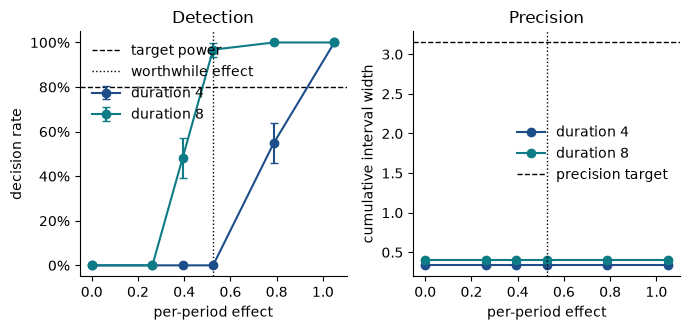

In [14]:
curve = power.frame()
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, FIG_HEIGHT))
for duration, color in ((4, COLOR_SHORT), (8, COLOR_LONG)):
    rows = curve[curve["duration"] == duration].sort_values("effect")
    axes[0].errorbar(
        rows["effect"],
        rows["probability"],
        yerr=rows["monte_carlo_error"],
        fmt="-o",
        color=color,
        label=f"duration {duration}",
        capsize=3,
    )
    axes[1].plot(
        rows["effect"],
        rows["interval_width"],
        "-o",
        color=color,
        label=f"duration {duration}",
    )
axes[0].axhline(
    TARGET_POWER, color="black", linestyle="--", linewidth=1, label="target power"
)
axes[0].axvline(
    WORTHWHILE, color="black", linestyle=":", linewidth=1, label="worthwhile effect"
)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
_style_axis(axes[0])
axes[0].set_xlabel("per-period effect")
axes[0].set_ylabel("decision rate")
axes[0].set_title("Detection")
axes[0].legend(frameon=False)

axes[1].axhline(
    PRECISION_TARGET,
    color="black",
    linestyle="--",
    linewidth=1,
    label="precision target",
)
axes[1].axvline(WORTHWHILE, color="black", linestyle=":", linewidth=1)
_style_axis(axes[1])
axes[1].set_xlabel("per-period effect")
axes[1].set_ylabel("cumulative interval width")
axes[1].set_title("Precision")
axes[1].legend(frameon=False)
fig.tight_layout()

In [15]:
diagnostics = one_experiment.evaluations[0].diagnostics
pd.Series(
    {
        "fits": power.n_fits,
        "replicates": power.n_replicates,
        "failed runs": power.failed_runs,
        "divergences": power.divergences,
        "max rhat": power.max_rhat,
        "preperiod RMSE ratio": power.preperiod_rmse_ratio,
        "one-experiment min bulk ESS": diagnostics.min_bulk_ess,
        "one-experiment max rhat": diagnostics.max_rhat,
    }
)

fits                             62.000000
replicates                       31.000000
failed runs                       0.000000
divergences                       0.000000
max rhat                          1.014522
preperiod RMSE ratio              0.952559
one-experiment min bulk ESS    1436.421845
one-experiment max rhat           1.007738
dtype: float64

The fit count is the cost of the comparison, not a tuning result. Sixty-two fits is the budget this tolerance and these two durations require. Both durations meet the precision target. The split is whether the minimum detectable effect is at or below the worthwhile effect. The diagnostics above are what the study returned. A failed diagnostic is a reason not to treat the curve as a precise ranking. Differences smaller than the Monte Carlo tolerance are not claimed. A few replicates print a convex-hull warning because the generator's noise can leave the donor range. That warning is not a failed fit.


## Dependence, and a screen that is not power

The main curve uses `correctly_specified_noisy_reference`. A second generator, `temporal_dependence`, adds AR(1) noise and is run at the longer duration only. It is a separate study with its own fit budget. It is not a second duration and not a reason to redraw the first curve.

A persistent-misfit generator is a third, smaller check. Its tolerance is loose because the claim is the screen, not a decision rate. If the screen fires, the result withholds power. The withheld rate is not reported as a small power.


In [16]:
dependent = ReferencePowerEvaluator(
    plan,
    history=frame,
    scenario_family="temporal_dependence",
)
with _QuietSampling():
    dependence = dependent.effect_by_duration(
        (8,),
        (0.0, WORTHWHILE),
        decision=decision,
        criterion=criterion,
        scale="absolute",
        minimum_worthwhile_effect=WORTHWHILE,
    )
comparison = pd.DataFrame(
    [
        {
            "generator": "correctly_specified_noisy_reference",
            "duration": 8,
            "false-positive rate": power.point(8, 0.0).false_positive_rate,
            "rate at worthwhile effect": power.point(8, WORTHWHILE).probability,
        },
        {
            "generator": "temporal_dependence",
            "duration": 8,
            "false-positive rate": dependence.point(8, 0.0).false_positive_rate,
            "rate at worthwhile effect": dependence.point(8, WORTHWHILE).probability,
        },
    ]
)
comparison

/var/folders/r0/nf1kgxsx6zx3rw16xc3wnnzr0000gn/T/ipykernel_15202/3781581934.py:6: UserWarning: Convex hull assumption may be violated: 1 pre-intervention time points (2.5% above, 0.0% below control range). The synthetic control method requires the treated unit to lie within the convex hull of control units. Consider: (1) adding more diverse control units, (2) using a model with an intercept (e.g., ITS with control predictors), or (3) using the Augmented Synthetic Control Method. See glossary term 'Convex hull condition' for more details.
/var/folders/r0/nf1kgxsx6zx3rw16xc3wnnzr0000gn/T/ipykernel_15202/3781581934.py:6: UserWarning: Convex hull assumption may be violated: 1 pre-intervention time points (0.0% above, 2.5% below control range). The synthetic control method requires the treated unit to lie within the convex hull of control units. Consider: (1) adding more diverse control units, (2) using a model with an intercept (e.g., ITS with control predictors), or (3) using the Augmente

,generator,duration,false-positive rate,rate at worthwhile effect
0,correctly_specified_noisy_reference,8,0.0,0.967742
1,temporal_dependence,8,0.0,0.838710


In [17]:
screen_criterion = PowerCriterion(
    target_power=TARGET_POWER,
    false_positive_tolerance=FALSE_POSITIVE_TOLERANCE,
    precision_target=None,
    monte_carlo_error_tolerance=0.25,
    qualification_scope="fixed_design",
)
misfit = ReferencePowerEvaluator(
    plan,
    history=frame,
    scenario_family="persistent_misfit",
)
with _QuietSampling():
    screen = misfit.effect_by_duration(
        (8,),
        (0.0,),
        decision=decision,
        criterion=screen_criterion,
        scale="absolute",
    )
pd.Series(
    {
        "power withheld": screen.power_withheld,
        "withhold reason": screen.withhold_reason,
        "fits": screen.n_fits,
    }
)

/var/folders/r0/nf1kgxsx6zx3rw16xc3wnnzr0000gn/T/ipykernel_15202/2458807445.py:13: UserWarning: Convex hull assumption may be violated: 40 pre-intervention time points (40.0% above, 60.0% below control range). The synthetic control method requires the treated unit to lie within the convex hull of control units. Consider: (1) adding more diverse control units, (2) using a model with an intercept (e.g., ITS with control predictors), or (3) using the Augmented Synthetic Control Method. See glossary term 'Convex hull condition' for more details.
/var/folders/r0/nf1kgxsx6zx3rw16xc3wnnzr0000gn/T/ipykernel_15202/2458807445.py:13: UserWarning: Convex hull assumption may be violated: 39 pre-intervention time points (37.5% above, 60.0% below control range). The synthetic control method requires the treated unit to lie within the convex hull of control units. Consider: (1) adding more diverse control units, (2) using a model with an intercept (e.g., ITS with control predictors), or (3) using the 

power withheld                                                  True
withhold reason    Pre-period misfit: simplex reconstruction fail...
fits                                                               4
dtype: object

The dependence row is one duration under a different generator. It does not extend the main curve. The misfit row is a screen. The output shows power withheld, not a decision rate. A withheld result is the finding. It is not a low power for the credible pool, and it is not the contrasting pool's failure. That failure was the audit trajectory.


## The duration to carry forward

A duration qualifies only when three public results agree. The false-positive rate is within tolerance. The precision flag at the zero effect is true. The minimum detectable effect was attained and is at or below the worthwhile effect. The shortest qualifying duration is the plan. If none qualify, the notebook stops at a written refusal. It does not loosen the tolerance, move the worthwhile effect, or call `run` on planning history.

The choice uses `correctly_specified_noisy_reference`. The dependence row and the misfit screen do not vote.


In [18]:
def duration_qualifies(result, duration):
    point = result.point(duration, 0.0)
    detectable = next(
        item for item in result.minimum_detectable_effects if item.duration == duration
    )
    return bool(
        point.false_positive_rate is not None
        and point.false_positive_rate <= FALSE_POSITIVE_TOLERANCE
        and point.precision_met is True
        and detectable.status == "attained"
        and detectable.worthwhile_comparison == "mde_at_or_below_worthwhile"
    )


choice_rows = []
for duration in DURATIONS:
    point = power.point(duration, 0.0)
    worth = power.point(duration, WORTHWHILE)
    detectable = next(
        item for item in power.minimum_detectable_effects if item.duration == duration
    )
    choice_rows.append(
        {
            "duration": duration,
            "false-positive rate": point.false_positive_rate,
            "precision met": point.precision_met,
            "interval width": point.interval_width,
            "rate at worthwhile effect": worth.probability,
            "mde": detectable.effect,
            "mde status": detectable.status,
            "worthwhile comparison": detectable.worthwhile_comparison,
            "qualifies": duration_qualifies(power, duration),
        }
    )
choice = pd.DataFrame(choice_rows)
qualifying = [int(row.duration) for row in choice.itertuples() if row.qualifies]
carried = min(qualifying) if qualifying else None
choice

,duration,false-positive rate,precision met,interval width,rate at worthwhile effect,mde,mde status,worthwhile comparison,qualifies
0,4,0.0,True,0.335371,0.000000,0.933404,attained,mde_larger_than_worthwhile,False
1,8,0.0,True,0.404778,0.967742,0.479323,attained,mde_at_or_below_worthwhile,True


In [19]:
if carried is None:
    print(
        "Neither duration qualifies. The next step is a different design, "
        "not a launch and not a longer search of this donor pool."
    )
    frozen = None
else:
    rejected = [duration for duration in DURATIONS if duration != carried]
    print(
        f"Carry forward duration {carried}. "
        f"Duration {rejected[0]} is the rejected arm of the same study."
    )
    handoff = plan.analysis_handoff(duration=carried)
    sampling = dict(handoff.sample_kwargs)
    print(
        "run() is not called here. The future-test tail is still simulated. "
        "The next call, after those periods are observed, is run() on a realized panel."
    )
    frozen = pd.Series(
        {
            "treated units": handoff.treated_units,
            "control units": handoff.control_units,
            "estimator": handoff.estimator,
            "estimand": handoff.decision.estimand,
            "threshold": handoff.decision.threshold,
            "direction": handoff.decision.direction,
            "probability": handoff.decision.probability,
            "treatment time": handoff.treatment_time,
            "holdout start": handoff.holdout_index[0],
            "holdout end": handoff.holdout_index[-1],
            "sampling seed": sampling["random_seed"],
            "draws": sampling["draws"],
            "tune": sampling["tune"],
            "chains": sampling["chains"],
        }
    )
frozen

Carry forward duration 8. Duration 4 is the rejected arm of the same study.
run() is not called here. The future-test tail is still simulated. The next call, after those periods are observed, is run() on a realized panel.


treated units                            (unit_a,)
control units     (unit_b, unit_c, unit_d, unit_e)
estimator                        synthetic_control
estimand                          cumulative_total
threshold                                 3.148834
direction                                 positive
probability                                    0.8
treatment time                                  40
holdout start                                   40
holdout end                                     47
sampling seed                                 1442
draws                                          500
tune                                           500
chains                                           4
dtype: object

The table is the choice. The sentence under it is that table applied to the rule. Carrying the short duration means the longer arm is not bought. Carrying the longer duration means the short arm did not clear the same bar. Carrying neither means the specification is the record of the refusal. The study is not refit to change that sentence.

The series under that sentence is the frozen analysis specification: units, decision, estimator, window, and sampling seed. It is what `run()` receives after the future-test periods are observed. The capabilities series in the next cell is not that specification. It only says which estimator path this plan can run.

`HistoryOnlyPlan` accepts an estimator name. The power study on this page uses the synthetic-control reference path only. Swapping in another estimator would be a different plan, not a column in this table. Augmented synthetic control and interactive fixed effects are not run.


In [20]:
capabilities = plan.capabilities
pd.Series(
    {
        "estimator": capabilities.estimator,
        "deterministic effect reuse": capabilities.deterministic_effect_reuse,
        "horizon reuse": capabilities.horizon_reuse,
        "post-period donor data": capabilities.post_period_donor_data,
        "group support": capabilities.group_support,
    }
)

estimator                     synthetic_control
deterministic effect reuse                 True
horizon reuse                             False
post-period donor data                     True
group support                             False
dtype: object

## What this page does not do

The panel is simulated. Units are generic. A training fit, however close, is not validation that the untreated path will stay a convex combination of the donors. The audit checks tracking on this simulated panel. It is not a proof that the donors will stay untreated, that the intervention will be unanticipated, or that units will not interfere.

The design is fixed. The duration grid, the donor pools, the worthwhile effect, and the precision target were declared before the power fits. The notebook does not add a duration after seeing which arm failed. It does not pick a rehearsal because its estimate looked friendlier. It does not treat a posterior interval as power, or a withheld rate as a small one.

The sampling settings are four chains, 500 tuning draws, and 500 posterior draws, with a target acceptance rate of 0.95. They are a planning budget, not a claim that every scientific ranking is resolved. The Monte Carlo tolerance caps the ranking, not the posterior interval.

:::{bibliography}
:filter: docname in docnames
:::
